In [1]:
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import matplotlib.patches as patches

# Chemin du dataset original (lecture seule)
BASE_PATH = '/kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset'
# Chemin de travail (écriture)
WORK_PATH = '/kaggle/working'

print("Bibliothèques importées !")
print(f"BASE_PATH : {BASE_PATH}")
print(f"WORK_PATH : {WORK_PATH}")

Bibliothèques importées !
BASE_PATH : /kaggle/input/datasets/a2015003713/militaryaircraftdetectiondataset
WORK_PATH : /kaggle/working


In [2]:
# Lister les fichiers du dataset
for item in os.listdir(BASE_PATH):
    print(item)

dataset
annotated_samples
labels_with_split.csv
crop


In [3]:
# Charger le CSV
df = pd.read_csv(f'{BASE_PATH}/labels_with_split.csv')

print(f"Nombre d'annotations : {len(df)}")
print(f"Nombre de classes    : {df['class'].nunique()}")
print(f"\nRépartition train/val/test :")
print(df['split'].value_counts())
print(f"\nListe des classes :")
print(sorted(df['class'].unique()))
print(f"\nAperçu :")
print(df.head())

Nombre d'annotations : 41441
Nombre de classes    : 101

Répartition train/val/test :
split
train         31127
validation     7545
test           2769
Name: count, dtype: int64

Liste des classes :
['A10', 'A400M', 'AG600', 'AH64', 'AKINCI', 'AV8B', 'An124', 'An22', 'An225', 'An72', 'B1', 'B2', 'B21', 'B52', 'Be200', 'C1', 'C130', 'C17', 'C2', 'C390', 'C5', 'CH47', 'CH53', 'CL415', 'E2', 'E7', 'EF2000', 'EMB314', 'F117', 'F14', 'F15', 'F16', 'F18', 'F2', 'F22', 'F35', 'F4', 'FCK1', 'H6', 'Il76', 'J10', 'J20', 'J35', 'J36', 'J50', 'JAS39', 'JF17', 'JH7', 'KAAN', 'KC135', 'KF21', 'KIZILELMA', 'KJ600', 'Ka27', 'Ka52', 'MQ20', 'MQ25', 'MQ28', 'MQ9', 'Mi24', 'Mi26', 'Mi28', 'Mi8', 'Mig29', 'Mig31', 'Mirage2000', 'NH90', 'P3', 'RQ4', 'Rafale', 'SR71', 'Su24', 'Su25', 'Su34', 'Su47', 'Su57', 'T50', 'TB001', 'TB2', 'Tejas', 'Tornado', 'Tu160', 'Tu22M', 'Tu95', 'U2', 'UH60', 'US2', 'V22', 'V280', 'Vulcan', 'WZ10', 'WZ7', 'WZ9', 'X29', 'X32', 'XB70', 'XQ58', 'Y20', 'YF23', 'Z10', 'Z19']

Aperçu

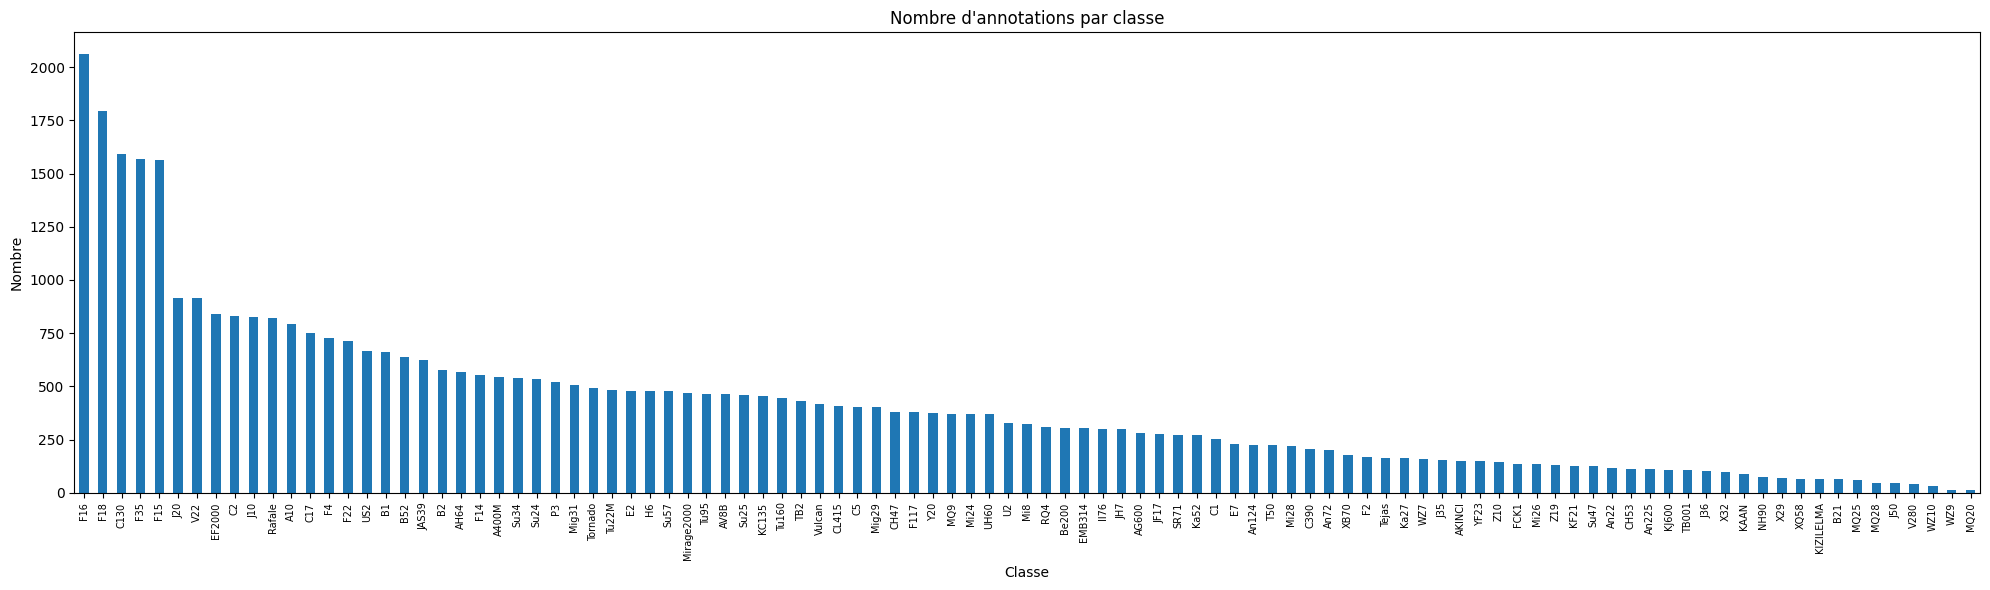

5 classes les moins représentées :
class
J50     46
V280    39
WZ10    32
WZ9     15
MQ20    11
Name: count, dtype: int64

5 classes les plus représentées :
class
F16     2061
F18     1796
C130    1590
F35     1569
F15     1564
Name: count, dtype: int64


In [4]:
# Visualiser le nombre d'annotations par classe
plt.figure(figsize=(20, 6))
df['class'].value_counts().plot(kind='bar')
plt.title('Nombre d\'annotations par classe')
plt.xlabel('Classe')
plt.ylabel('Nombre')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

print("5 classes les moins représentées :")
print(df['class'].value_counts().tail())
print("\n5 classes les plus représentées :")
print(df['class'].value_counts().head())

Nombre de classes dans crop/ : 101
Nombre total d'images crop   : 41441

5 classes les plus représentées :
  F16             : 2061 images
  F18             : 1796 images
  C130            : 1590 images
  F35             : 1569 images
  F15             : 1564 images

5 classes les moins représentées :
  J50             : 46 images
  V280            : 39 images
  WZ10            : 32 images
  WZ9             : 15 images
  MQ20            : 11 images


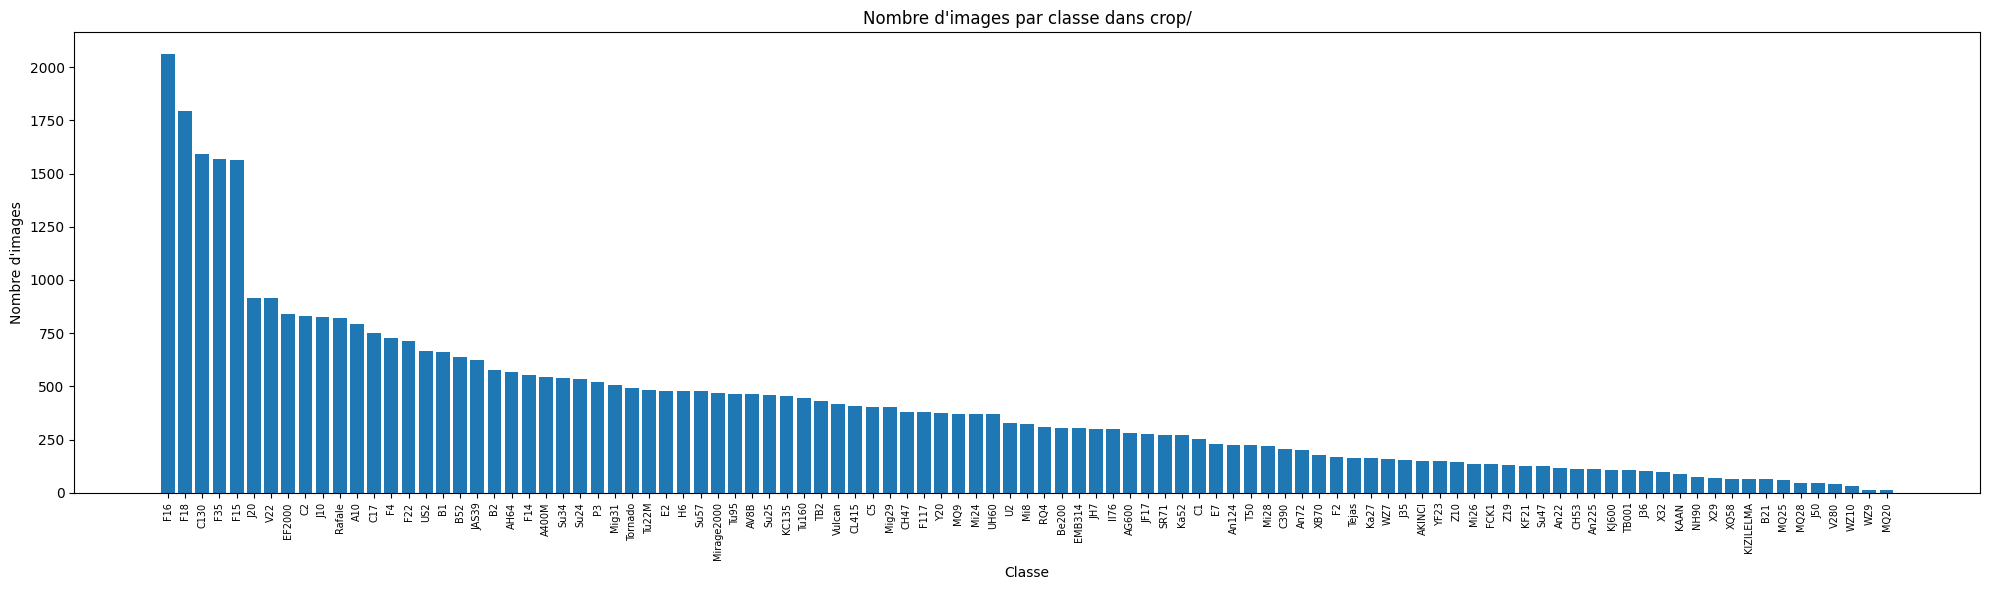

In [5]:
crop_path = f'{BASE_PATH}/crop'

class_counts = {}
for class_name in os.listdir(crop_path):
    class_folder = f'{crop_path}/{class_name}'
    if os.path.isdir(class_folder):
        count = len([f for f in os.listdir(class_folder) if f.endswith('.jpg')])
        class_counts[class_name] = count

class_counts = dict(sorted(class_counts.items(), key=lambda x: x[1], reverse=True))

print(f"Nombre de classes dans crop/ : {len(class_counts)}")
print(f"Nombre total d'images crop   : {sum(class_counts.values())}")
print(f"\n5 classes les plus représentées :")
for cls, cnt in list(class_counts.items())[:5]:
    print(f"  {cls:15s} : {cnt} images")
print(f"\n5 classes les moins représentées :")
for cls, cnt in list(class_counts.items())[-5:]:
    print(f"  {cls:15s} : {cnt} images")

plt.figure(figsize=(20, 6))
plt.bar(class_counts.keys(), class_counts.values())
plt.title('Nombre d\'images par classe dans crop/')
plt.xlabel('Classe')
plt.ylabel('Nombre d\'images')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

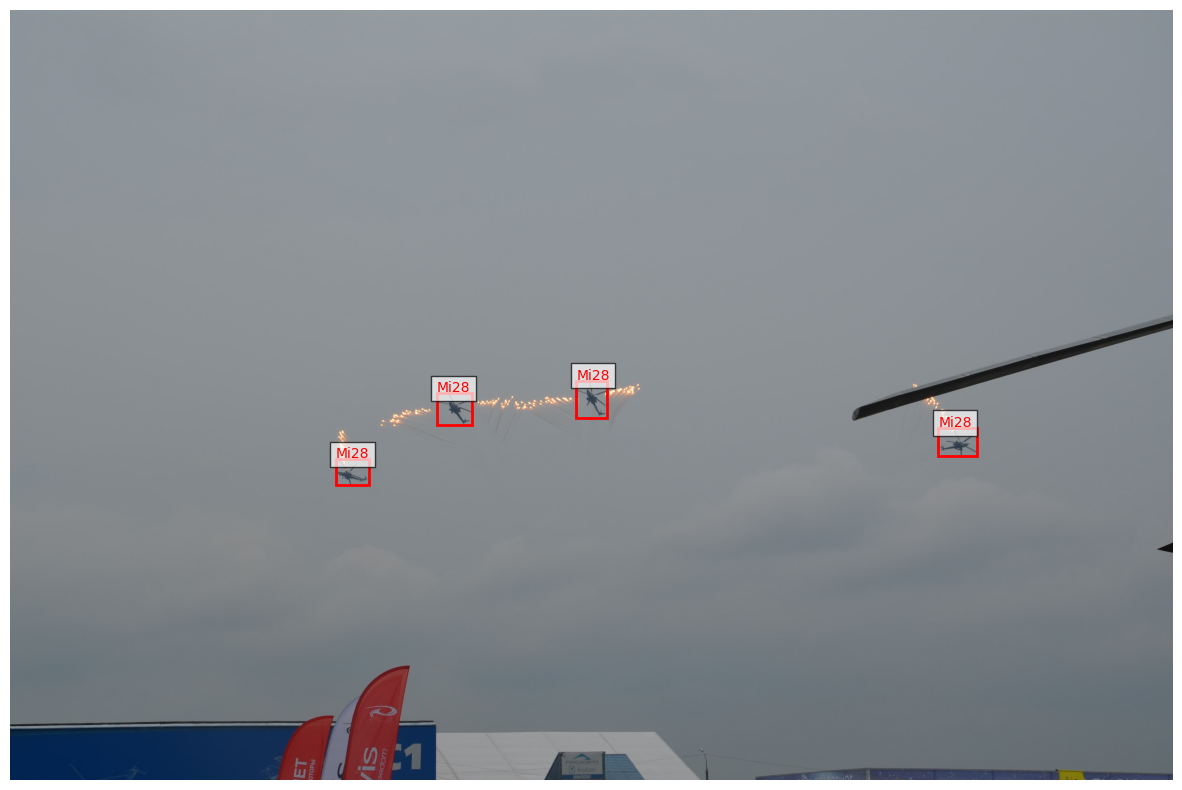

In [6]:
def show_image_with_boxes(filename, df, base_path):
    img_path = f'{base_path}/dataset/{filename}.jpg'
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    fig, ax = plt.subplots(1, figsize=(12, 8))
    ax.imshow(img)
    
    boxes = df[df['filename'] == filename]
    for _, row in boxes.iterrows():
        x, y = row['xmin'], row['ymin']
        w = row['xmax'] - row['xmin']
        h = row['ymax'] - row['ymin']
        rect = patches.Rectangle((x, y), w, h,
                    linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        ax.text(x, y-5, row['class'], color='red', fontsize=10,
                bbox=dict(facecolor='white', alpha=0.7))
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Tester sur la première image
first_img = df['filename'].iloc[0]
show_image_with_boxes(first_img, df, BASE_PATH)

In [7]:
before = len(df)

# Supprimer bbox inversées
df = df[(df['xmax'] > df['xmin']) & (df['ymax'] > df['ymin'])]
# Supprimer bbox hors image
df = df[(df['xmin'] >= 0) & (df['ymin'] >= 0)]
df = df[(df['xmax'] <= df['width']) & (df['ymax'] <= df['height'])]
# Supprimer bbox trop petites
df = df[((df['xmax'] - df['xmin']) >= 10) & ((df['ymax'] - df['ymin']) >= 10)]

after = len(df)
print(f"Avant nettoyage : {before}")
print(f"Après nettoyage : {after}")
print(f"Supprimées      : {before - after} bbox invalides")

Avant nettoyage : 41441
Après nettoyage : 41382
Supprimées      : 59 bbox invalides


In [8]:
classes = sorted(df['class'].unique())
class_to_id = {c: i for i, c in enumerate(classes)}
id_to_class = {i: c for c, i in class_to_id.items()}

print(f"Nombre de classes : {len(classes)}")
print(f"Exemple : F16 → {class_to_id['F16']}, Rafale → {class_to_id['Rafale']}")

# Sauvegarder
with open(f'{WORK_PATH}/classes.txt', 'w') as f:
    f.write('\n'.join(classes))
print("classes.txt sauvegardé !")

Nombre de classes : 101
Exemple : F16 → 31, Rafale → 69
classes.txt sauvegardé !


In [9]:
for split in ['train', 'val', 'test']:
    os.makedirs(f'{WORK_PATH}/yolo_dataset/{split}/images', exist_ok=True)
    os.makedirs(f'{WORK_PATH}/yolo_dataset/{split}/labels', exist_ok=True)

print("Structure créée :")
for split in ['train', 'val', 'test']:
    print(f"  yolo_dataset/{split}/images/")
    print(f"  yolo_dataset/{split}/labels/")

Structure créée :
  yolo_dataset/train/images/
  yolo_dataset/train/labels/
  yolo_dataset/val/images/
  yolo_dataset/val/labels/
  yolo_dataset/test/images/
  yolo_dataset/test/labels/


In [10]:
df['split'] = df['split'].replace('validation', 'val')

skipped = 0
converted = 0

for filename, group in df.groupby('filename'):
    split = group['split'].iloc[0]
    img_src = f'{BASE_PATH}/dataset/{filename}.jpg'
    
    if not os.path.exists(img_src):
        skipped += 1
        continue
    
    shutil.copy(img_src, f'{WORK_PATH}/yolo_dataset/{split}/images/{filename}.jpg')
    
    label_path = f'{WORK_PATH}/yolo_dataset/{split}/labels/{filename}.txt'
    with open(label_path, 'w') as f:
        for _, row in group.iterrows():
            cid = class_to_id[row['class']]
            cx = ((row['xmin'] + row['xmax']) / 2) / row['width']
            cy = ((row['ymin'] + row['ymax']) / 2) / row['height']
            bw = (row['xmax'] - row['xmin']) / row['width']
            bh = (row['ymax'] - row['ymin']) / row['height']
            cx, cy, bw, bh = [max(0, min(1, v)) for v in [cx, cy, bw, bh]]
            f.write(f"{cid} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")
    converted += 1

print(f"Convertis : {converted} images")
print(f"Ignorés   : {skipped} images")

Convertis : 23126 images
Ignorés   : 0 images


In [11]:
yaml_content = f"""path: {WORK_PATH}/yolo_dataset
train: train/images
val: val/images
test: test/images

nc: {len(classes)}
names: {classes}
"""

with open(f'{WORK_PATH}/aircraft.yaml', 'w') as f:
    f.write(yaml_content)

print("aircraft.yaml créé !")
print(yaml_content)

aircraft.yaml créé !
path: /kaggle/working/yolo_dataset
train: train/images
val: val/images
test: test/images

nc: 101
names: ['A10', 'A400M', 'AG600', 'AH64', 'AKINCI', 'AV8B', 'An124', 'An22', 'An225', 'An72', 'B1', 'B2', 'B21', 'B52', 'Be200', 'C1', 'C130', 'C17', 'C2', 'C390', 'C5', 'CH47', 'CH53', 'CL415', 'E2', 'E7', 'EF2000', 'EMB314', 'F117', 'F14', 'F15', 'F16', 'F18', 'F2', 'F22', 'F35', 'F4', 'FCK1', 'H6', 'Il76', 'J10', 'J20', 'J35', 'J36', 'J50', 'JAS39', 'JF17', 'JH7', 'KAAN', 'KC135', 'KF21', 'KIZILELMA', 'KJ600', 'Ka27', 'Ka52', 'MQ20', 'MQ25', 'MQ28', 'MQ9', 'Mi24', 'Mi26', 'Mi28', 'Mi8', 'Mig29', 'Mig31', 'Mirage2000', 'NH90', 'P3', 'RQ4', 'Rafale', 'SR71', 'Su24', 'Su25', 'Su34', 'Su47', 'Su57', 'T50', 'TB001', 'TB2', 'Tejas', 'Tornado', 'Tu160', 'Tu22M', 'Tu95', 'U2', 'UH60', 'US2', 'V22', 'V280', 'Vulcan', 'WZ10', 'WZ7', 'WZ9', 'X29', 'X32', 'XB70', 'XQ58', 'Y20', 'YF23', 'Z10', 'Z19']



In [12]:
for split in ['train', 'val', 'test']:
    n_images = len(os.listdir(f'{WORK_PATH}/yolo_dataset/{split}/images'))
    n_labels = len(os.listdir(f'{WORK_PATH}/yolo_dataset/{split}/labels'))
    print(f"{split:6s} → {n_images} images | {n_labels} labels")

example_label = os.listdir(f'{WORK_PATH}/yolo_dataset/train/labels')[0]
print(f"\nExemple label :")
with open(f'{WORK_PATH}/yolo_dataset/train/labels/{example_label}') as f:
    print(f.read())

train  → 17326 images | 17326 labels
val    → 4256 images | 4256 labels
test   → 1544 images | 1544 labels

Exemple label :
3 0.415739 0.361715 0.154319 0.111871
3 0.624760 0.411436 0.130902 0.094469
3 0.746257 0.460534 0.131286 0.096955
3 0.875816 0.474829 0.120921 0.090740



In [13]:
!pip install ultralytics -q
from ultralytics import YOLO
print("YOLOv8 installé !")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 26.1 MB/s eta 0:00:0000:01
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YOLOv8 installé !


In [14]:
# Charger le modèle pré-entraîné YOLOv8 small
model = YOLO('yolov8s.pt')

# Lancer l'entraînement
results = model.train(
    data=f'{WORK_PATH}/aircraft.yaml',
    epochs=50,          # nombre de passages sur le dataset
    imgsz=640,          # taille des images
    batch=16,           # nombre d'images par batch
    patience=10,        # arrêt si pas d'amélioration après 10 epochs
    device=0,           # GPU
    project=f'{WORK_PATH}/runs',
    name='yolov8_aircraft',
    save=True,
    plots=True
)

Ultralytics 8.4.22 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/aircraft.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8_aircraft, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patienc

In [15]:
# Charger le meilleur modèle sauvegardé
best_model = YOLO(f'{WORK_PATH}/runs/yolov8_aircraft/weights/best.pt')

# Évaluer sur le split test
metrics = best_model.val(
    data=f'{WORK_PATH}/aircraft.yaml',
    split='test'
)

print(f"mAP@0.5      : {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95 : {metrics.box.map:.4f}")
print(f"Précision    : {metrics.box.mp:.4f}")
print(f"Rappel       : {metrics.box.mr:.4f}")

Ultralytics 8.4.22 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 73 layers, 11,164,671 parameters, 0 gradients, 28.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3192.8±1340.9 MB/s, size: 482.0 KB)
val: Scanning /kaggle/working/yolo_dataset/test/labels... 1544 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1544/1544 1.5Kit/s 1.0s0.0s
val: New cache created: /kaggle/working/yolo_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 6.0it/s 16.2s0.3s
                   all       1544       2764      0.724      0.577      0.671      0.598
                   A10         35         62      0.764      0.628      0.798      0.676
                 A400M         32         39      0.779      0.722      0.798      0.731
                 AG600         14         17      0.813      0.706       0.75      0.673
                  AH64         22   


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1544 /kaggle/working/yolo_dataset/test/images/f0055552c8a0538a76b175765f443b97.jpg: 448x640 1 F35, 50.1ms
image 2/1544 /kaggle/working/yolo_dataset/test/images/f006aa612a2e0922813d7070136b3445.jpg: 448x640 (no detections), 6.7ms
image 3/1544 /kaggle/working/yolo_dataset/test/images/f007598dacc4b6baa1aae36229c4d594.jpg: 480x640 1 Su57, 49.0ms
image 4/1544 /kaggle/working/yolo_dataset/test/images/f007a9bac628e561239f6ca9f5fa61fc.jpg: 448x640 1 A400

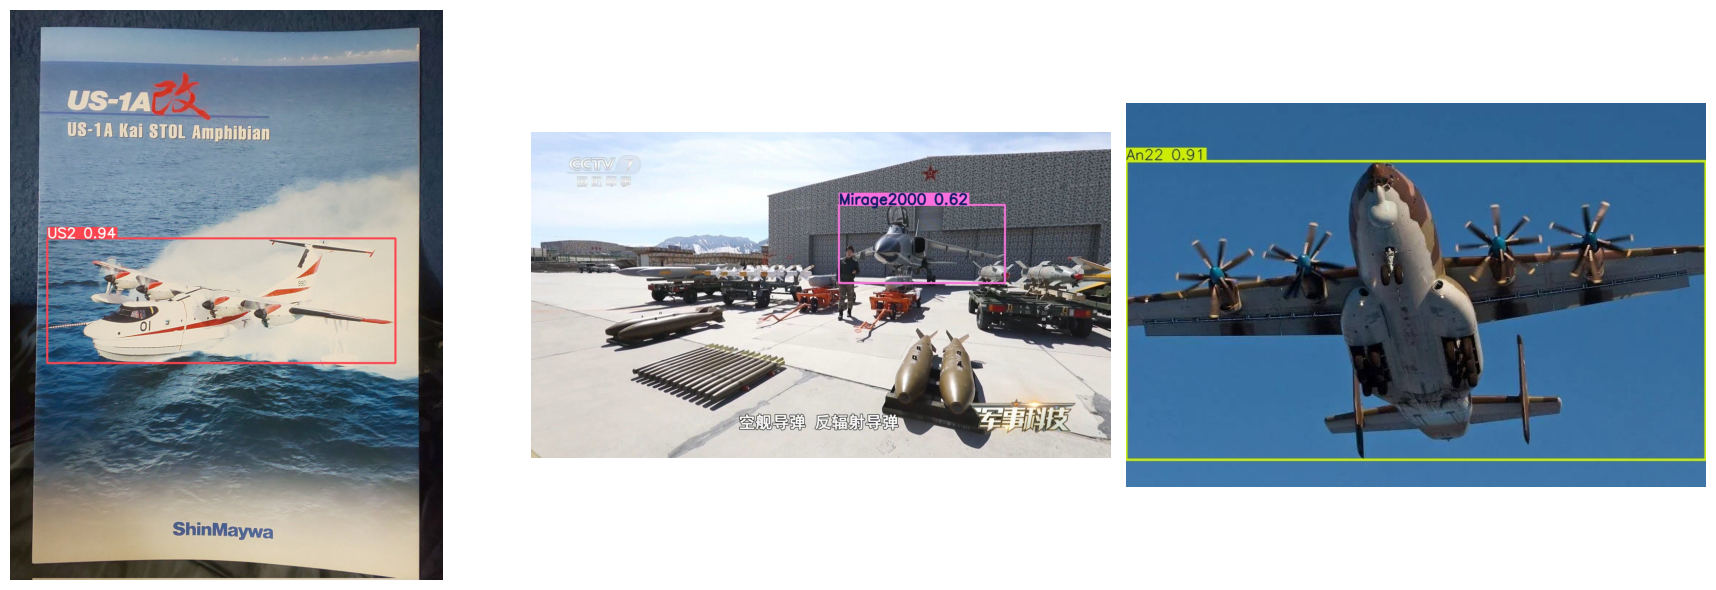

In [18]:
# Tester sur quelques images du split test
test_results = best_model.predict(
    source=f'{WORK_PATH}/yolo_dataset/test/images',
    conf=0.25,
    save=True,
    project=f'{WORK_PATH}/predictions'
)

# Afficher 3 images avec les détections
import glob
pred_images = glob.glob(f'{WORK_PATH}/predictions/**/*.jpg', recursive=True)[:3]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img_path in zip(axes, pred_images):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [24]:
import os
best_pt = f'{WORK_PATH}/runs/yolov8_aircraft/weights/best.pt'
print(f"best.pt existe : {os.path.exists(best_pt)}")
print(f"Taille : {os.path.getsize(best_pt) / (1024**2):.1f} MB")

best.pt existe : True
Taille : 21.5 MB
